

# Sleap Health and Daily Performance dataset analysis


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
sleep_data=pd.read_csv("/content/drive/My Drive/Egyetem/Diplomamunka/Source/sleep_health_dataset.csv")
sleep_data.head()

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1,29,Female,Driver,25.7,Japan,6.19,6.6,22.5,19.3,...,63,0,0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0
1,2,55,Female,Software Engineer,22.0,USA,8.32,6.9,26.9,14.9,...,52,1,0,18.0,0.13,Winter,Weekend,99.4,Healthy,1
2,3,42,Male,Nurse,25.0,India,3.74,1.0,20.2,16.2,...,72,0,1,17.9,1.67,Spring,Weekend,2.5,Severe,0
3,4,37,Female,Student,29.5,India,6.79,6.4,17.7,17.7,...,71,0,0,19.1,2.37,Summer,Weekend,67.8,Healthy,0
4,5,23,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,...,71,0,0,19.7,1.26,Summer,Weekday,38.1,Mild,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Feature Engineering:

Az olyan oszlopokat ahol szövegesen vannak az adatok és az alvásprofil létrehozásához hasznosak lehetnek átalakítjuk számokká

In [ ]:
sleep_data = pd.get_dummies(sleep_data, columns=['gender'], drop_first=True) #onehot
#Bináris, sorrendi kódolás
sleep_data['is_weekend'] = sleep_data['day_type'].map({'Weekday': 0, 'Weekend': 1})
sleep_data['chronotype_code'] = sleep_data['chronotype'].map({'Morning': 0, 'Neutral': 1, 'Evening': 2})
# Kódolás növekvő kockázati skálára (0: egészséges -> 3: súlyos)
risk_mapping = {
    'Healthy': 0,
    'Mild': 1,
    'Moderate': 2,
    'Severe': 3
}

sleep_data['sleep_disorder_risk_score'] = sleep_data['sleep_disorder_risk'].map(risk_mapping)

Korreláció vizsgálatból kizárom azokat az oszlopokat amik nem kellenek, mert a user nem tudná megadni pl, rem, mélyalvás %, szoba hőmérséklet, pulzus és az ID se kell
A felt-rested is kiszűrhető mert másnapi következmény, és nem ok


In [ ]:
# A kizárni kívánt oszlopok listája
exclude_cols = [
    'person_id',
    'cognitive_performance_score',
    'rem_percentage',
    'deep_sleep_percentage',
    'heart_rate_resting_bpm',
    'room_temperature_celsius',
    'felt_rested'
]

# Kiválasztjuk a numerikus és boolean oszlopokat, majd a bool-okat int-re konvertáljuk
selected_cols = sleep_data.select_dtypes(include=['float64', 'int64', 'bool']).copy()
for col in selected_cols.select_dtypes(include=['bool']).columns:
    selected_cols[col] = selected_cols[col].astype(int)

# Kizárjuk a nem kívánt oszlopokat
filtered_numeric_cols = selected_cols.drop(columns=exclude_cols, errors='ignore')

# Új korrelációs mátrix kiszámítása
filtered_corr_matrix = filtered_numeric_cols.corr()

# Az alvásminőséggel (sleep_quality_score) való korrelációk kinyerése és rendezése
filtered_sleep_quality_corr = filtered_corr_matrix['sleep_quality_score'].drop('sleep_quality_score', errors='ignore')

# Eredmények DataFrame-be rendezése
filtered_factors_df = pd.DataFrame({
    'Korreláció (r)': filtered_sleep_quality_corr,
    'Kapcsolat Erőssége (Abszolút)': filtered_sleep_quality_corr.abs()
}).sort_values(by='Kapcsolat Erőssége (Abszolút)', ascending=False)

print("Az alvásminőséget leginkább befolyásoló szűrt tényezők sorrendben (már a kódolt oszlopokkal együtt):")
display(filtered_factors_df)

Az alvásminőséget leginkább befolyásoló szűrt tényezők sorrendben (már a kódolt oszlopokkal együtt):


,Korreláció (r),Kapcsolat Erőssége (Abszolút)
sleep_disorder_risk_score,-0.693763,0.693763
sleep_duration_hrs,0.646462,0.646462
stress_score,-0.638828,0.638828
wake_episodes_per_night,-0.381230,0.381230
work_hours_that_day,-0.368638,0.368638
sleep_latency_mins,-0.292933,0.292933
is_weekend,0.276064,0.276064
shift_work,-0.263407,0.263407
alcohol_units_before_bed,-0.080920,0.080920
screen_time_before_bed_mins,-0.079158,0.079158


In [ ]:
# Csoportosítás az edzés napja (exercise_day) szerint, és a lépésszámok átlagának kiszámítása
exercise_steps = sleep_data.groupby('exercise_day')['steps_that_day'].agg(['mean', 'median', 'count']).reset_index()
exercise_steps.columns = ['Edzés Napja (0=Nem, 1=Igen)', 'Átlagos Lépésszám', 'Medián Lépésszám', 'Megfigyelések Száma']

display(exercise_steps)

,"Edzés Napja (0=Nem, 1=Igen)",Átlagos Lépésszám,Medián Lépésszám,Megfigyelések Száma
0,0,5853.353456,5812.0,54929
1,1,9499.836303,9497.0,45071


A lépésszám és az edzésnap közötti korrelációs együttható: 0.5243



/tmp/ipykernel_1206/4277107268.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='exercise_day', y='steps_that_day', data=sleep_data, palette='Set2')


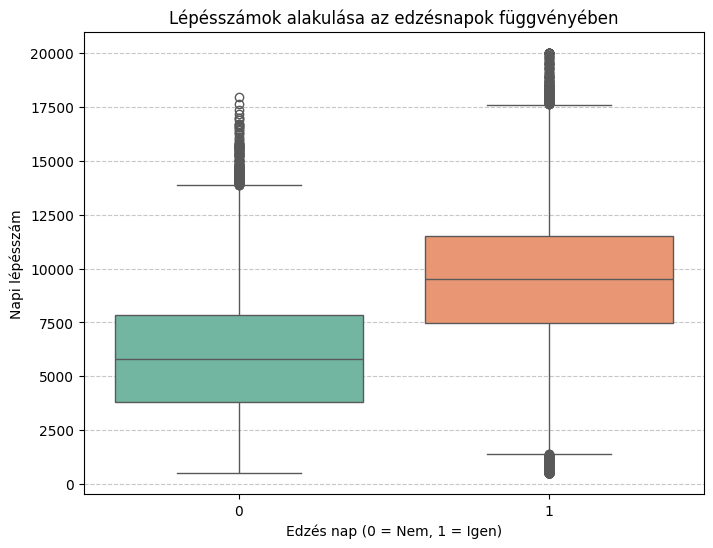

In [ ]:
# Korreláció kiszámítása a két változó között
correlation = sleep_data['steps_that_day'].corr(sleep_data['exercise_day'])
print(f"A lépésszám és az edzésnap közötti korrelációs együttható: {correlation:.4f}\n")

# Vizualizáció boxplot segítségével
plt.figure(figsize=(8, 6))
sns.boxplot(x='exercise_day', y='steps_that_day', data=sleep_data, palette='Set2')
plt.title('Lépésszámok alakulása az edzésnapok függvényében')
plt.xlabel('Edzés nap (0 = Nem, 1 = Igen)')
plt.ylabel('Napi lépésszám')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
def classify_activity(row):
    steps = row.get('steps_that_day', 0)
    exercise = row.get('exercise_day', 0)

    # 2: Magas aktivitás (edzésnap VAGY legalább 10 000 lépés)
    if exercise == 1 or steps >= 10000:
        return 2
    # 1: Mérsékelt aktivitás (nincs edzés, de 5 000 - 9 999 lépés megvan)
    elif steps >= 5000:
        return 1
    # 0: Mozgásszegény (nincs edzés és < 5 000 lépés)
    else:
        return 0

# Új oszlop létrehozása a sleep_data DataFrame-ben:
sleep_data['activity_level'] = sleep_data.apply(classify_activity, axis=1)

print(sleep_data['activity_level'].value_counts().sort_index())

activity_level
0    21512
1    28952
2    49536
Name: count, dtype: int64


In [ ]:
# A kizárni kívánt oszlopok listája
exclude_cols = [
    'person_id',
    'cognitive_performance_score',
    'rem_percentage',
    'deep_sleep_percentage',
    'heart_rate_resting_bpm',
    'room_temperature_celsius',
    'felt_rested',
    #kikerül a két mozgással kapcsolatos oszlop
    'exercise_day',
    'steps_that_day'
]

# Kiválasztjuk a numerikus és boolean oszlopokat, majd a bool-okat int-re konvertáljuk
selected_cols = sleep_data.select_dtypes(include=['float64', 'int64', 'bool']).copy()
for col in selected_cols.select_dtypes(include=['bool']).columns:
    selected_cols[col] = selected_cols[col].astype(int)

# Kizárjuk a nem kívánt oszlopokat
filtered_numeric_cols = selected_cols.drop(columns=exclude_cols, errors='ignore')

# Új korrelációs mátrix kiszámítása
filtered_corr_matrix = filtered_numeric_cols.corr()

# Az alvásminőséggel (sleep_quality_score) való korrelációk kinyerése és rendezése
filtered_sleep_quality_corr = filtered_corr_matrix['sleep_quality_score'].drop('sleep_quality_score', errors='ignore')

# Eredmények DataFrame-be rendezése
filtered_factors_df = pd.DataFrame({
    'Korreláció (r)': filtered_sleep_quality_corr,
    'Kapcsolat Erőssége (Abszolút)': filtered_sleep_quality_corr.abs()
}).sort_values(by='Kapcsolat Erőssége (Abszolút)', ascending=False)

print("Az alvásminőséget leginkább befolyásoló szűrt tényezők sorrendben (az activity type-al):")
display(filtered_factors_df)

Az alvásminőséget leginkább befolyásoló szűrt tényezők sorrendben (az activity type-al):


,Korreláció (r),Kapcsolat Erőssége (Abszolút)
sleep_disorder_risk_score,-0.693763,0.693763
sleep_duration_hrs,0.646462,0.646462
stress_score,-0.638828,0.638828
wake_episodes_per_night,-0.381230,0.381230
work_hours_that_day,-0.368638,0.368638
sleep_latency_mins,-0.292933,0.292933
is_weekend,0.276064,0.276064
shift_work,-0.263407,0.263407
alcohol_units_before_bed,-0.080920,0.080920
screen_time_before_bed_mins,-0.079158,0.079158


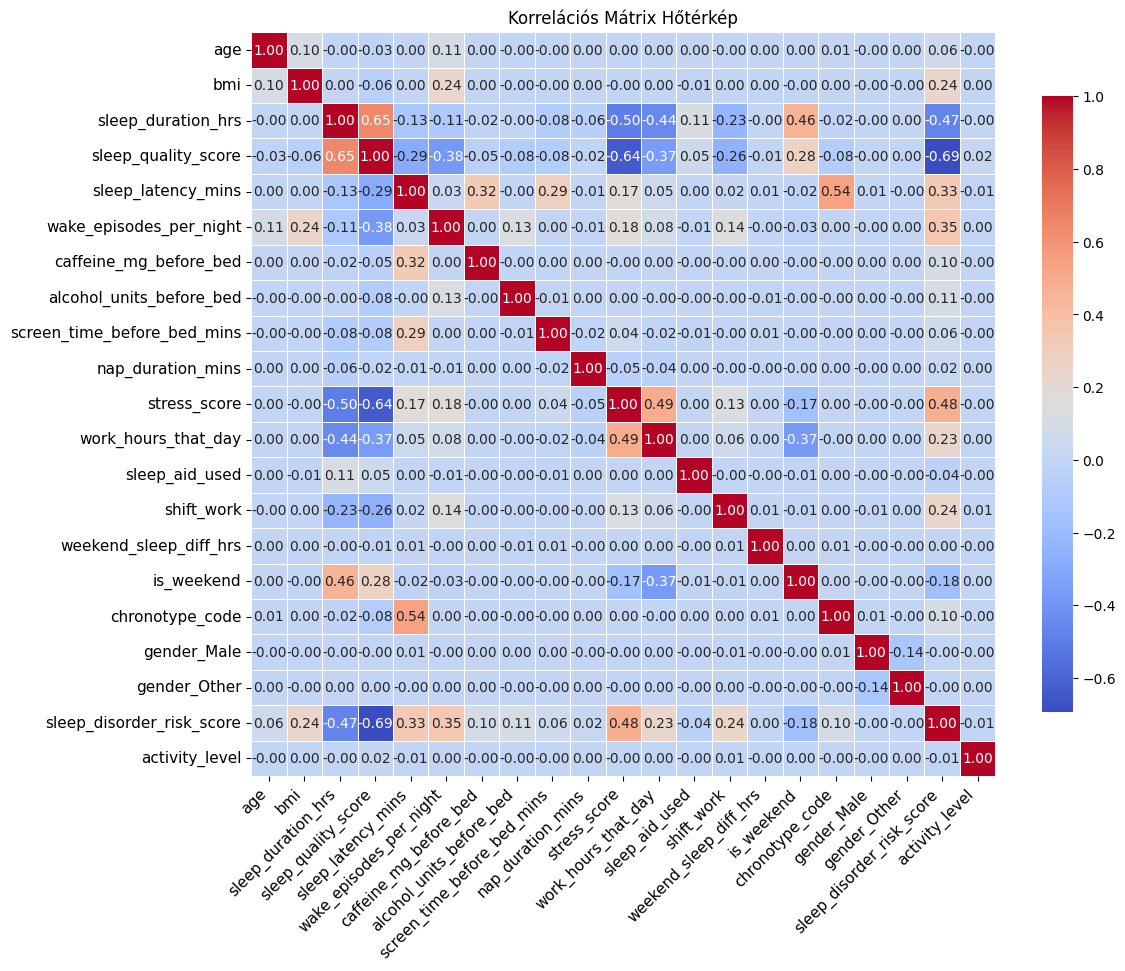

In [ ]:

# Korrelációs mátrix kiszámítása
corr_matrix = filtered_numeric_cols.corr()

# Hőtérkép kirajzolása
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,           # Számok megjelenítése
    fmt=".2f",            # Két tizedesjegy
    cmap='coolwarm',      # Kék-fehér-piros skála
    square=True,          # KÉNYSZERÍTI a négyzet alakot
    linewidths=.5,        # Kis köz a cellák között
    cbar_kws={"shrink": .8}, # A színskála ne legyen hosszabb a térképnél
    annot_kws={"size": 10}   # A számok betűmérete
)
plt.title('Korrelációs Mátrix Hőtérkép')
# 3. Tengelyfeliratok igazítása
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)

plt.show()

In [ ]:
#Hiányzó elemek vizsgálata

In [ ]:
key_cols = ['sleep_duration_hrs', 'stress_score', 'sleep_latency_mins',
            'wake_episodes_per_night', 'activity_level', 'sleep_disorder_risk_score']
print(sleep_data[key_cols].isnull().sum())

sleep_duration_hrs           0
stress_score                 0
sleep_latency_mins           0
wake_episodes_per_night      0
activity_level               0
sleep_disorder_risk_score    0
dtype: int64
